In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import local_binary_pattern
from PIL import Image

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Feature engineering environment ready!")

Feature engineering environment ready!


In [2]:
from src.feature_extraction import extract_features

real_folder = (
    PROJECT_ROOT / "dataset" / "raw" /
    "CIFAKE" / "train" / "REAL"
)

sample_image = next(real_folder.glob("*.jpg"))

features = extract_features(sample_image)

print("Image:", sample_image.name)
print("Number of features:", len(features))
print("Feature vector shape:", features.shape)

print("\nFeature vector:")
print(features)

Image: 0000 (10).jpg
Number of features: 24
Feature vector shape: (24,)

Feature vector:
[7.03125000e-02 9.57031250e-02 5.85937500e-02 1.11328125e-01
 2.00195312e-01 1.51367188e-01 5.95703125e-02 7.03125000e-02
 5.07812500e-02 1.31835938e-01 1.98974487e+02 1.00446129e+01
 1.30342773e+02 6.16406441e+01 0.00000000e+00 2.55000000e+02
 1.30325195e+02 6.02846336e+01 0.00000000e+00 2.55000000e+02
 1.30274414e+02 5.84135971e+01 2.00000000e+00 2.55000000e+02]


In [4]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "dataset" / "raw" / "CIFAKE"

train_path = DATASET_PATH / "train"

print("Dataset path:", DATASET_PATH)
print("Training path:", train_path)
random.seed(42)

train_path = DATASET_PATH / "train"

real_folder = train_path / "REAL"
fake_folder = train_path / "FAKE"

real_images = list(real_folder.glob("*.jpg"))
fake_images = list(fake_folder.glob("*.jpg"))

real_samples = random.sample(real_images, 1000)
fake_samples = random.sample(fake_images, 1000)

print("REAL sample:", len(real_samples))
print("FAKE sample:", len(fake_samples))

Dataset path: c:\Users\KIIT\Desktop\HybridDeepTrace\dataset\raw\CIFAKE
Training path: c:\Users\KIIT\Desktop\HybridDeepTrace\dataset\raw\CIFAKE\train
REAL sample: 1000
FAKE sample: 1000


In [5]:
real_features = []
fake_features = []

print("Extracting REAL features...")

for i, image_path in enumerate(real_samples):
    real_features.append(extract_features(image_path))

    if (i + 1) % 100 == 0:
        print(f"REAL: {i + 1}/1000")

print("\nExtracting FAKE features...")

for i, image_path in enumerate(fake_samples):
    fake_features.append(extract_features(image_path))

    if (i + 1) % 100 == 0:
        print(f"FAKE: {i + 1}/1000")

real_features = np.array(real_features)
fake_features = np.array(fake_features)

print("\nExtraction complete!")
print("REAL shape:", real_features.shape)
print("FAKE shape:", fake_features.shape)

Extracting REAL features...
REAL: 100/1000
REAL: 200/1000
REAL: 300/1000
REAL: 400/1000
REAL: 500/1000
REAL: 600/1000
REAL: 700/1000
REAL: 800/1000
REAL: 900/1000
REAL: 1000/1000

Extracting FAKE features...
FAKE: 100/1000
FAKE: 200/1000
FAKE: 300/1000
FAKE: 400/1000
FAKE: 500/1000
FAKE: 600/1000
FAKE: 700/1000
FAKE: 800/1000
FAKE: 900/1000
FAKE: 1000/1000

Extraction complete!
REAL shape: (1000, 24)
FAKE shape: (1000, 24)


In [6]:
feature_names = (
    [f"LBP_{i}" for i in range(10)]
    + ["DCT_low", "DCT_high"]
    + [
        f"{channel}_{stat}"
        for channel in ["R", "G", "B"]
        for stat in ["mean", "std", "min", "max"]
    ]
)

comparison = pd.DataFrame({
    "Feature": feature_names,
    "REAL_mean": real_features.mean(axis=0),
    "FAKE_mean": fake_features.mean(axis=0)
})

comparison["Absolute_difference"] = abs(
    comparison["REAL_mean"] - comparison["FAKE_mean"]
)

comparison.sort_values(
    "Absolute_difference",
    ascending=False
)

,Feature,REAL_mean,FAKE_mean,Absolute_difference
20,B_mean,111.570457,100.470665,11.099792
12,R_mean,125.160217,115.921959,9.238258
14,R_min,15.704000,6.743000,8.961000
18,G_min,14.180000,5.314000,8.866000
16,G_mean,122.612091,114.047546,8.564545
22,B_min,9.419000,4.051000,5.368000
10,DCT_low,171.792969,168.408432,3.384537
19,G_max,234.076996,237.335007,3.258011
15,R_max,237.778000,240.970993,3.192993
17,G_std,50.443111,52.871899,2.428787


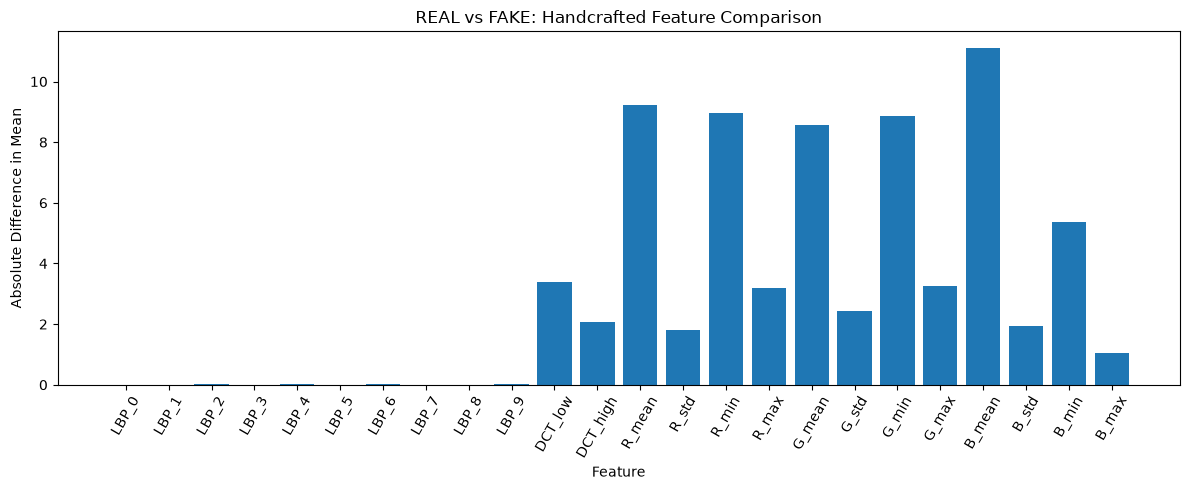

In [7]:
plt.figure(figsize=(12, 5))

plt.bar(
    comparison["Feature"],
    comparison["Absolute_difference"]
)

plt.xlabel("Feature")
plt.ylabel("Absolute Difference in Mean")
plt.title("REAL vs FAKE: Handcrafted Feature Comparison")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [8]:
import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

real_folder = train_path / "REAL"
fake_folder = train_path / "FAKE"

real_images = list(real_folder.glob("*.jpg"))
fake_images = list(fake_folder.glob("*.jpg"))

real_samples = random.sample(real_images, 1000)
fake_samples = random.sample(fake_images, 1000)

print("REAL sample:", len(real_samples))
print("FAKE sample:", len(fake_samples))

REAL sample: 1000
FAKE sample: 1000


In [9]:
real_features = []
fake_features = []

print("Extracting REAL features...")

for i, image_path in enumerate(real_samples):
    real_features.append(extract_features(image_path))

    if (i + 1) % 100 == 0:
        print(f"REAL: {i + 1}/1000")

print("\nExtracting FAKE features...")

for i, image_path in enumerate(fake_samples):
    fake_features.append(extract_features(image_path))

    if (i + 1) % 100 == 0:
        print(f"FAKE: {i + 1}/1000")

import numpy as np

real_features = np.array(real_features)
fake_features = np.array(fake_features)

print("\nExtraction complete!")
print("REAL shape:", real_features.shape)
print("FAKE shape:", fake_features.shape)

Extracting REAL features...
REAL: 100/1000
REAL: 200/1000
REAL: 300/1000
REAL: 400/1000
REAL: 500/1000
REAL: 600/1000
REAL: 700/1000
REAL: 800/1000
REAL: 900/1000
REAL: 1000/1000

Extracting FAKE features...
FAKE: 100/1000
FAKE: 200/1000
FAKE: 300/1000
FAKE: 400/1000
FAKE: 500/1000
FAKE: 600/1000
FAKE: 700/1000
FAKE: 800/1000
FAKE: 900/1000
FAKE: 1000/1000

Extraction complete!
REAL shape: (1000, 24)
FAKE shape: (1000, 24)


In [10]:
feature_names = (
    [f"LBP_{i}" for i in range(10)]
    + ["DCT_low", "DCT_high"]
    + [
        f"{channel}_{stat}"
        for channel in ["R", "G", "B"]
        for stat in ["mean", "std", "min", "max"]
    ]
)

comparison = pd.DataFrame({
    "Feature": feature_names,
    "REAL_mean": real_features.mean(axis=0),
    "FAKE_mean": fake_features.mean(axis=0)
})

comparison["Absolute_difference"] = abs(
    comparison["REAL_mean"] - comparison["FAKE_mean"]
)

comparison = comparison.sort_values(
    "Absolute_difference",
    ascending=False
)

comparison

,Feature,REAL_mean,FAKE_mean,Absolute_difference
20,B_mean,111.570457,100.470665,11.099792
12,R_mean,125.160217,115.921959,9.238258
14,R_min,15.704000,6.743000,8.961000
18,G_min,14.180000,5.314000,8.866000
16,G_mean,122.612091,114.047546,8.564545
22,B_min,9.419000,4.051000,5.368000
10,DCT_low,171.792969,168.408432,3.384537
19,G_max,234.076996,237.335007,3.258011
15,R_max,237.778000,240.970993,3.192993
17,G_std,50.443111,52.871899,2.428787


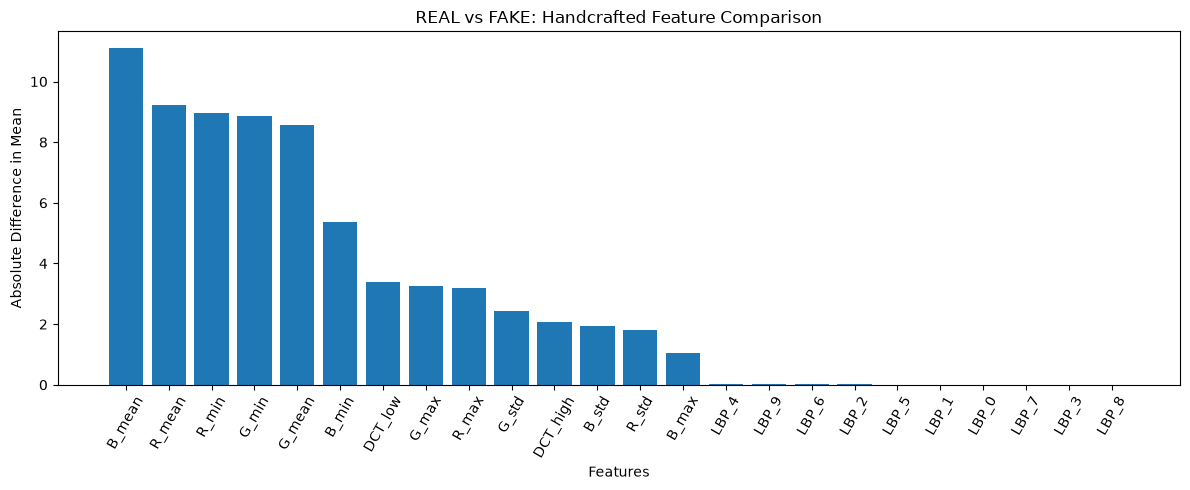

In [11]:
plt.figure(figsize=(12, 5))

plt.bar(
    comparison["Feature"],
    comparison["Absolute_difference"]
)

plt.xlabel("Features")
plt.ylabel("Absolute Difference in Mean")
plt.title("REAL vs FAKE: Handcrafted Feature Comparison")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Combine REAL and FAKE features
X = np.vstack((real_features, fake_features))

# REAL = 0, FAKE = 1
y = np.concatenate((
    np.zeros(len(real_features)),
    np.ones(len(fake_features))
))

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

print("REAL images:", np.sum(y == 0))
print("FAKE images:", np.sum(y == 1))

Features shape: (2000, 24)
Labels shape: (2000,)
REAL images: 1000
FAKE images: 1000


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training features: (1600, 24)
Validation features: (400, 24)
Training labels: (1600,)
Validation labels: (400,)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled validation data:", X_val_scaled.shape)

Scaled training data: (1600, 24)
Scaled validation data: (400, 24)


In [15]:
from sklearn.svm import SVC

svm_model = SVC(kernel="rbf", random_state=42)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = svm_model.predict(X_val_scaled)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1-score:", f1_score(y_val, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        target_names=["REAL", "FAKE"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy: 0.885
Precision: 0.8928571428571429
Recall: 0.875
F1-score: 0.8838383838383839

Classification Report:
              precision    recall  f1-score   support

        REAL       0.88      0.90      0.89       200
        FAKE       0.89      0.88      0.88       200

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.88       400
weighted avg       0.89      0.89      0.88       400


Confusion Matrix:
[[179  21]
 [ 25 175]]


In [17]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models"

MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(svm_model, MODEL_PATH / "svm_model.pkl")
joblib.dump(scaler, MODEL_PATH / "scaler.pkl")

print("SVM model saved successfully!")
print("Scaler saved successfully!")

SVM model saved successfully!
Scaler saved successfully!


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

rf_pred = rf_model.predict(X_val)

print("Random Forest Results")
print("----------------------")

print("Accuracy:", accuracy_score(y_val, rf_pred))
print("Precision:", precision_score(y_val, rf_pred))
print("Recall:", recall_score(y_val, rf_pred))
print("F1-score:", f1_score(y_val, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

Random Forest Results
----------------------
Accuracy: 0.88
Precision: 0.8653846153846154
Recall: 0.9
F1-score: 0.8823529411764706

Confusion Matrix:
[[172  28]
 [ 20 180]]


In [20]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_PATH / "random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [21]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost installed successfully!")

XGBoost version: 3.2.0
XGBoost installed successfully!


In [22]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

xgb_pred = xgb_model.predict(X_val)

print("XGBoost Results")
print("----------------")

print("Accuracy:", accuracy_score(y_val, xgb_pred))
print("Precision:", precision_score(y_val, xgb_pred))
print("Recall:", recall_score(y_val, xgb_pred))
print("F1-score:", f1_score(y_val, xgb_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        xgb_pred,
        target_names=["REAL", "FAKE"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, xgb_pred))

XGBoost Results
----------------
Accuracy: 0.8775
Precision: 0.8793969849246231
Recall: 0.875
F1-score: 0.8771929824561403

Classification Report:
              precision    recall  f1-score   support

        REAL       0.88      0.88      0.88       200
        FAKE       0.88      0.88      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400


Confusion Matrix:
[[176  24]
 [ 25 175]]


In [24]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(
    xgb_model,
    MODEL_PATH / "xgboost_model.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!
